# 05 · Modelos finales del objetivo 1 y registro de modelos en MLflow

Proyecto «Playlist perfecta para viajes en grupo» · NPD Entertainment · CEBANC · Ander Ameztoy

El notebook 03 dejó los modelos base (error en el lote 2: MAE ≈ 0,21, sin ganar a la media de la persona) y el 04 mostró por qué: los hábitos cambian con el tiempo y conviene entrenar con los **últimos 18 meses**. Aquí:

1. Se añade una referencia más exigente (la **mediana** de cada persona) y se comparan los modelos del 03 con un Gradient Boosting que optimiza directamente el MAE (`loss="absolute_error"`), con **búsqueda de hiperparámetros** por validación cruzada.
2. Se entrena con dos periodos: el lote 1 completo y la ventana de 18 meses (enero 2024 a junio 2025). La prueba es siempre el lote 2 completo, una sola vez al final.
3. Se **analizan los errores**: dónde falla el modelo y por qué.
4. Se **registran los modelos en el registro de MLflow** (`playlist_tasa_no_salto`) con versiones, y se justifica cuál pasa a producción (alias `produccion`).

Uso de IA (nivel VERDE): notebook escrito con ayuda de Claude y revisado por Ander.

## 0. Configuración

In [18]:
from pathlib import Path
import os, json, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, chi2_contingency
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import spearmanr
import joblib
warnings.filterwarnings("ignore", category=UserWarning)

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/proyecto-Ebaluacion1")
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

HISTORIALES = {
    "ander":  RAIZ / "data" / "entrada" / "historial" / "ander",
    "daniel": RAIZ / "data" / "entrada" / "historial" / "daniel",
}
CAMPOS = ["ts", "ms_played", "spotify_track_uri", "master_metadata_track_name", "master_metadata_album_artist_name",
          "master_metadata_album_album_name", "reason_end", "shuffle", "platform"]
ZONA = "Europe/Madrid"
CORTE = pd.Timestamp("2025-07-01", tz=ZONA)          # lote 1 < corte <= lote 2
CORTE_PRUEBA = pd.Timestamp("2026-01-01", tz=ZONA)   # experimento de reentrenamiento (sección 4)
MIN_ESCUCHAS, UMBRAL_SALTO_MS, SEMILLA = 5, 30_000, 42

COLOR = {"ander": "#56BE91", "daniel": "#FD3B1F"}
NEGRO, GRIS = "#020202", "#B9B6AE"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
FIGURAS = RAIZ / "notebooks" / "figuras"; FIGURAS.mkdir(parents=True, exist_ok=True)
SALIDA = RAIZ / "data" / "salida"; SALIDA.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    ruta = FIGURAS / f"{nombre}.png"; fig.savefig(ruta, dpi=200, bbox_inches="tight"); return ruta
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| raíz:", RAIZ)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorno: Google Colab | raíz: /content/drive/MyDrive/proyecto-Ebaluacion1


### MLflow

Como en los notebooks 03 y 04. El registro de modelos necesita una base de datos (SQLite o el servidor del Docker); con la carpeta `mlruns/` no funciona.

In [19]:
try:
    import mlflow
except ImportError:
    if EN_COLAB:
        os.system("pip install -q mlflow"); import mlflow
    else:
        mlflow = None; print("AVISO: mlflow no está instalado; los resultados se calculan igual pero no se registran.")

if mlflow is not None:
    uri = os.environ.get("MLFLOW_TRACKING_URI")
    if uri is None:
        try:
            import urllib.request
            urllib.request.urlopen("http://localhost:5000", timeout=2); uri = "http://localhost:5000"
        except Exception:
            carpeta_mlflow = Path("/content/mlflow") if EN_COLAB else RAIZ / "mlflow"
            carpeta_mlflow.mkdir(parents=True, exist_ok=True)
            previa = RAIZ / "mlflow" / "mlflow.db"
            if EN_COLAB and previa.exists() and not (carpeta_mlflow / "mlflow.db").exists():
                import shutil; shutil.copy2(previa, carpeta_mlflow / "mlflow.db")
                print("Partimos de los experimentos guardados en", previa)
            os.chdir(carpeta_mlflow)
            uri = f"sqlite:///{carpeta_mlflow / 'mlflow.db'}"
    mlflow.set_tracking_uri(uri); mlflow.set_experiment("objetivo1_modelos_finales")
    print("MLflow en:", uri)

def registrar(nombre, params, metricas, figuras=()):
    if mlflow is None: return
    with mlflow.start_run(run_name=nombre):
        mlflow.log_params(params)
        mlflow.log_metrics({k: float(v) for k, v in metricas.items() if pd.notna(v)})
        for f in figuras: mlflow.log_artifact(str(f))

MLflow en: sqlite:////content/mlflow/mlflow.db


## 1. Datos

Se usan las mismas escuchas y la misma tabla persona × canción × contexto que en el notebook 04 (reconstruida desde los historiales para poder elegir el periodo de entrenamiento; cuadra con `gold.objetivo1` con un 3 % de diferencia por los filtros de silver).

In [20]:
def leer(carpeta, persona):
    ficheros = sorted(glob.glob(str(carpeta / "**" / "Streaming_History_Audio_*.json"), recursive=True))
    filas = []
    for f in ficheros:
        with open(f, encoding="utf-8") as fh:
            filas += [{k: r.get(k) for k in CAMPOS} for r in json.load(fh)]
    d = pd.DataFrame(filas, columns=CAMPOS); d["persona"] = persona
    return d

h = pd.concat([leer(c, p) for p, c in HISTORIALES.items()], ignore_index=True)
h["ms_played"] = pd.to_numeric(h["ms_played"])
h = h[h["spotify_track_uri"].notna() & (h["ms_played"] > 0)].copy()
h["track_id"] = h["spotify_track_uri"].str.replace("spotify:track:", "", regex=False)
h = h.sort_values("ms_played", ascending=False).drop_duplicates(["persona", "ts", "track_id"]).copy()
h["artista"] = h["master_metadata_album_artist_name"].fillna("?")
h["album"] = h["master_metadata_album_album_name"].fillna("?")
h["hora_local"] = pd.to_datetime(h["ts"], utc=True).dt.tz_convert(ZONA)
h["franja"] = h["hora_local"].dt.hour // 4                                   # 0-5, como en silver
h["tipo_dia"] = np.where(h["hora_local"].dt.dayofweek >= 5, "fin_semana", "laborable")
h["contexto"] = h["franja"].astype(str) + "·" + h["tipo_dia"]
h["lote"] = np.where(h["hora_local"] < CORTE, 1, 2)
h["mes"] = h["hora_local"].dt.tz_localize(None).dt.to_period("M")
h["no_salto"] = ~((h["reason_end"] == "fwdbtn") & (h["ms_played"] < UMBRAL_SALTO_MS))
h["shuffle"] = h["shuffle"].astype(bool)
h = h.sort_values("hora_local").reset_index(drop=True)

resumen = h.groupby(["persona", "lote"]).agg(
    reproducciones=("track_id", "size"), desde=("hora_local", "min"), hasta=("hora_local", "max"),
    meses=("mes", "nunique"), tasa_no_salto=("no_salto", "mean"))
resumen["desde"] = resumen["desde"].dt.date; resumen["hasta"] = resumen["hasta"].dt.date
resumen.round(3)

reproducciones       desde       hasta  meses  tasa_no_salto
persona lote                                                              
ander   1             147210  2019-05-10  2025-06-30     73          0.552
        2             108564  2025-07-01  2026-10-21     16          0.435
daniel  1              45612  2020-10-02  2025-06-30     51          0.936
        2              39229  2025-07-01  2026-11-17     17          0.923

In [21]:
def recuentos(d):
    """Escuchas y no saltos por persona × canción × contexto (los 'recuentos' de los que salen las variables)."""
    return (d.groupby(["persona", "track_id", "franja", "tipo_dia"])
             .agg(n_escuchas=("no_salto", "size"), n_no_salto=("no_salto", "sum"),
                  artista=("artista", "first"), album=("album", "first")).reset_index())

def tabla(etiquetas, fuente_d):
    """Filas con etiqueta de 'etiquetas' y variables de persona y grupo calculadas con 'fuente_d' (como gold.sql)."""
    t = recuentos(etiquetas)
    t["tasa_no_salto"] = t["n_no_salto"] / t["n_escuchas"]
    t["per_pct_shuffle"] = t["persona"].map(fuente_d.groupby("persona")["shuffle"].mean())
    pt = fuente_d.groupby(["persona", "track_id"])["no_salto"].agg(["size", "sum"])
    gt = pt.groupby("track_id").sum()
    own = pt.reindex(pd.MultiIndex.from_frame(t[["persona", "track_id"]])).fillna(0).to_numpy()
    tot = gt.reindex(t["track_id"]).fillna(0).to_numpy()
    n, ns = tot[:, 0] - own[:, 0], tot[:, 1] - own[:, 1]
    t["grp_n_escuchas"] = n
    t["grp_tasa_no_salto"] = np.where(n > 0, ns / np.maximum(n, 1), np.nan)
    return t

def tasa_suave(ns, n, previa, k=5):
    return (ns + k * previa) / (n + k)

def codificar(filas, src):
    f = filas[["persona", "track_id", "artista", "album", "franja", "tipo_dia"]].copy()
    per = src.groupby("persona")[["n_escuchas", "n_no_salto"]].sum()
    f["per_tasa"] = f["persona"].map(per["n_no_salto"] / per["n_escuchas"])
    ctx = src.groupby(["persona", "franja", "tipo_dia"])[["n_escuchas", "n_no_salto"]].sum()
    f = f.join((ctx["n_no_salto"] / ctx["n_escuchas"]).rename("ctx_tasa"), on=["persona", "franja", "tipo_dia"])
    propia = src.groupby(["persona", "track_id"])[["n_escuchas", "n_no_salto"]].sum()
    f = f.join(propia.rename(columns=lambda c: "own_" + c), on=["persona", "track_id"])
    for nombre, claves in [("art", ["persona", "artista"]), ("alb", ["persona", "artista", "album"])]:
        g = src.groupby(claves)[["n_escuchas", "n_no_salto"]].sum()
        f = f.join(g.rename(columns=lambda c: f"{nombre}_{c}_tot"), on=claves)
        n = (f[f"{nombre}_n_escuchas_tot"].fillna(0) - f["own_n_escuchas"].fillna(0)).clip(lower=0)
        ns = (f[f"{nombre}_n_no_salto_tot"].fillna(0) - f["own_n_no_salto"].fillna(0)).clip(lower=0)
        f[f"{nombre}_n"] = np.log1p(n)
        f[f"{nombre}_tasa"] = tasa_suave(ns, n, f["per_tasa"])
        f[f"{nombre}_conocido"] = (n > 0).astype(int)
    return f

def matriz(filas, cod):
    X = pd.DataFrame({
        "per_tasa": cod["per_tasa"], "ctx_tasa": cod["ctx_tasa"].fillna(cod["per_tasa"]),
        "art_tasa": cod["art_tasa"], "art_n": cod["art_n"], "art_conocido": cod["art_conocido"],
        "alb_tasa": cod["alb_tasa"], "alb_n": cod["alb_n"], "alb_conocido": cod["alb_conocido"],
        "per_pct_shuffle": filas["per_pct_shuffle"].to_numpy(),
        "grp_n": np.log1p(filas["grp_n_escuchas"].clip(lower=0)).to_numpy(),
        "grp_tasa": filas["grp_tasa_no_salto"].fillna(cod["per_tasa"]).to_numpy(),
        "grp_conocido": filas["grp_tasa_no_salto"].notna().astype(int).to_numpy(),
        "fin_semana": (filas["tipo_dia"] != "laborable").astype(int).to_numpy(),
    }, index=filas.index)
    for f in range(6):
        X[f"franja_{f}"] = (filas["franja"].astype(int) == f).astype(int).to_numpy()
    return X

def variables_oof(filas, src, k=5):
    partes = []
    for tr, te in GroupKFold(k).split(filas, groups=filas["track_id"]):
        sub = src[~src["track_id"].isin(set(filas.iloc[te]["track_id"]))]
        partes.append(matriz(filas.iloc[te], codificar(filas.iloc[te], sub)))
    return pd.concat(partes).loc[filas.index]

def ridge():
    return make_pipeline(StandardScaler(), Ridge(alpha=1.0))

def entrenar(periodo):
    """Entrena la Ridge con las filas fiables de 'periodo' (variables fuera de pliegue, pesos sqrt(n) como en el 03)."""
    t = tabla(periodo, periodo)
    t = t[t["n_escuchas"] >= MIN_ESCUCHAS].reset_index(drop=True)
    src = recuentos(periodo)
    X = variables_oof(t, src)
    m = ridge(); m.fit(X, t["tasa_no_salto"], ridge__sample_weight=np.sqrt(t["n_escuchas"]))
    return m, src, t, X

def evaluar(modelo, src, entreno_d, prueba_d, min_escuchas=MIN_ESCUCHAS):
    t = tabla(prueba_d, entreno_d)
    t = t[t["n_escuchas"] >= min_escuchas].reset_index(drop=True)
    X = matriz(t, codificar(t, src))
    t["prevista"] = np.clip(modelo.predict(X), 0, 1)
    t["base1"] = X["per_tasa"].to_numpy()
    t["cancion_nueva"] = X["art_conocido"].eq(0) & ~t.set_index(["persona", "track_id"]).index.isin(
        src.set_index(["persona", "track_id"]).index)
    return t

In [22]:
l1, l2 = h[h["lote"] == 1], h[h["lote"] == 2]
PERIODOS = {
    "lote 1 completo": l1,
    "ventana 18 meses": l1[l1["hora_local"] >= CORTE - pd.DateOffset(months=18)],
}
DATOS = {}
for nombre, periodo in PERIODOS.items():
    t = tabla(periodo, periodo)
    t = t[t["n_escuchas"] >= MIN_ESCUCHAS].reset_index(drop=True)
    src = recuentos(periodo)
    X = variables_oof(t, src)                                   # variables fuera de pliegue (sin fuga), como en el 03
    te = tabla(l2, periodo)
    te = te[te["n_escuchas"] >= MIN_ESCUCHAS].reset_index(drop=True)
    Xte = matriz(te, codificar(te, src))
    conocidas = set(zip(src["persona"], src["track_id"]))
    te["cancion_conocida"] = [(p, c) in conocidas for p, c in zip(te["persona"], te["track_id"])]
    DATOS[nombre] = dict(t=t, X=X, src=src, te=te, Xte=Xte, periodo=periodo)
    print(f"{nombre:17} entrenamiento {len(t):6,} filas ({periodo['hora_local'].min():%Y-%m} a {periodo['hora_local'].max():%Y-%m}) | prueba lote 2 {len(te):,} filas".replace(",", "."))
COLUMNAS = list(DATOS["lote 1 completo"]["X"].columns)
print("Variables:", ", ".join(COLUMNAS))

lote 1 completo   entrenamiento 11.595 filas (2019-05 a 2025-06) | prueba lote 2 8.920 filas
ventana 18 meses  entrenamiento  7.753 filas (2024-01 a 2025-06) | prueba lote 2 8.920 filas
Variables: per_tasa, ctx_tasa, art_tasa, art_n, art_conocido, alb_tasa, alb_n, alb_conocido, per_pct_shuffle, grp_n, grp_tasa, grp_conocido, fin_semana, franja_0, franja_1, franja_2, franja_3, franja_4, franja_5


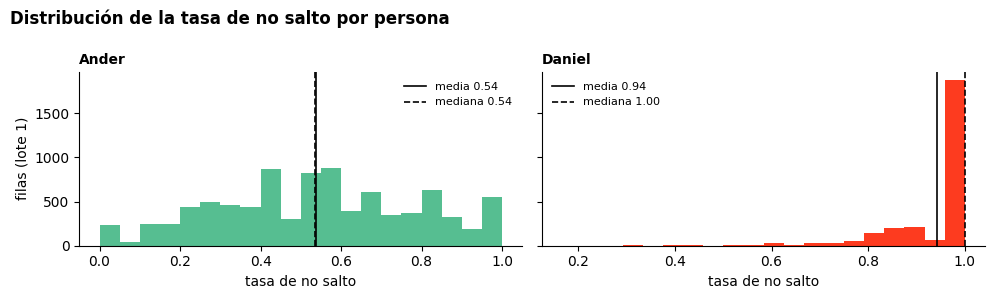

In [23]:
# Cómo es la variable objetivo: muchas filas en 1 (nunca se salta) y una cola de canciones que se saltan mucho
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, (p, d) in zip(axes, DATOS["lote 1 completo"]["t"].groupby("persona")):
    ax.hist(d["tasa_no_salto"], bins=20, color=COLOR[p])
    ax.axvline(d["tasa_no_salto"].mean(), color=NEGRO, lw=1.2, label=f"media {d['tasa_no_salto'].mean():.2f}")
    ax.axvline(d["tasa_no_salto"].median(), color=NEGRO, lw=1.2, ls="--", label=f"mediana {d['tasa_no_salto'].median():.2f}")
    ax.set_title(p.capitalize(), fontsize=10); ax.legend(frameon=False, fontsize=8); ax.set_xlabel("tasa de no salto")
axes[0].set_ylabel("filas (lote 1)")
fig.suptitle("Distribución de la tasa de no salto por persona", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig_dist = guardar(fig, "05_distribucion_objetivo"); plt.show()

La distribución es muy asimétrica (en Daniel casi todo está en 1). Con el MAE como métrica, la **mediana** de cada persona es mejor referencia que la media, y conviene un modelo que optimice el error absoluto y no el cuadrático.

## 2. Candidatos y búsqueda de hiperparámetros

| Modelo | Qué es |
| --- | --- |
| Base: media | tasa media de la persona (modelo base 1 del 03) |
| Base: mediana | tasa mediana de la persona (referencia nueva, más exigente con el MAE) |
| Ridge | el elegido en el 03 (`alpha` buscado por validación) |
| GB cuadrático | el Gradient Boosting del 03 |
| GB absoluto | Gradient Boosting con `loss="absolute_error"` y búsqueda aleatoria de 12 combinaciones |

Validación: `GroupKFold(5)` por canción dentro de cada periodo de entrenamiento (la misma canción nunca está en entrenamiento y validación a la vez). Las variables de cada fila ya están calculadas fuera de pliegue.

In [24]:
class Mediana:
    """Mediana de la tasa de cada persona en el entrenamiento (necesita saber de quién es cada fila)."""
    def fit(self, personas, y):
        self.tabla_ = pd.Series(np.asarray(y)).groupby(np.asarray(personas)).median(); return self
    def predict(self, personas):
        return pd.Series(np.asarray(personas)).map(self.tabla_).to_numpy()

class Media:
    """Tasa media de la persona: es la variable per_tasa (modelo base 1 del 03)."""
    def fit(self, X, y, **_): return self
    def predict(self, X): return X["per_tasa"].to_numpy()

def crear(tipo, **p):
    if tipo == "Ridge": return make_pipeline(StandardScaler(), Ridge(alpha=p.get("alpha", 1.0)))
    if tipo == "GB cuadrático": return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=40, random_state=SEMILLA)
    if tipo == "GB absoluto": return HistGradientBoostingRegressor(loss="absolute_error", random_state=SEMILLA, **p)
    return {"Base: media": Media, "Base: mediana": Mediana}[tipo]()

def ajustar(m, X, y, w):
    if isinstance(m, Media): return m.fit(X, y)
    if hasattr(m, "steps"): return m.fit(X, y, ridge__sample_weight=w)
    return m.fit(X, y, sample_weight=w)

def validar(tipo, d, p={}, pesos=True):
    t, X = d["t"], d["X"]; y = t["tasa_no_salto"].to_numpy(); w = np.sqrt(t["n_escuchas"].to_numpy()) if pesos else None
    pred = np.zeros(len(t))
    for tr, va in GroupKFold(5).split(X, groups=t["track_id"]):
        if tipo == "Base: mediana":
            pred[va] = Mediana().fit(t["persona"].iloc[tr], y[tr]).predict(t["persona"].iloc[va]); continue
        m = ajustar(crear(tipo, **p), X.iloc[tr], y[tr], None if w is None else w[tr])
        pred[va] = np.clip(m.predict(X.iloc[va]), 0, 1)
    return mean_absolute_error(y, pred)

rng = np.random.default_rng(SEMILLA)
ESPACIO = [{"learning_rate": float(rng.choice([0.02, 0.05, 0.1])), "max_iter": int(rng.choice([150, 300, 500])),
            "max_leaf_nodes": int(rng.choice([7, 15, 31])), "min_samples_leaf": int(rng.choice([20, 40, 80, 150])),
            "l2_regularization": float(rng.choice([0.0, 1.0]))} for _ in range(12)]

busqueda, mejores = [], {}
for periodo, d in DATOS.items():
    for alpha in [0.1, 1, 10, 100]:
        busqueda.append({"periodo": periodo, "modelo": "Ridge", "params": {"alpha": alpha}, "pesos": True, "cv_mae": validar("Ridge", d, {"alpha": alpha})})
    for p in ESPACIO:
        for pesos in (True, False):
            busqueda.append({"periodo": periodo, "modelo": "GB absoluto", "params": p, "pesos": pesos, "cv_mae": validar("GB absoluto", d, p, pesos)})
    for tipo in ["Base: media", "Base: mediana", "GB cuadrático"]:
        busqueda.append({"periodo": periodo, "modelo": tipo, "params": {}, "pesos": True, "cv_mae": validar(tipo, d)})
busqueda = pd.DataFrame(busqueda)
for (periodo, modelo), g in busqueda.groupby(["periodo", "modelo"]):
    mejores[(periodo, modelo)] = g.loc[g["cv_mae"].idxmin()]
tabla_busqueda = pd.DataFrame([{"periodo": k[0], "modelo": k[1], "mejor cv_mae": v["cv_mae"], "pesos sqrt(n)": v["pesos"], "hiperparámetros": v["params"]}
                               for k, v in mejores.items()]).sort_values(["periodo", "mejor cv_mae"])
busqueda.assign(params=busqueda["params"].astype(str)).to_csv(SALIDA / "05_busqueda_hiperparametros.csv", index=False)
tabla_busqueda.round(4)

,periodo,modelo,mejor cv_mae,pesos sqrt(n),hiperparámetros
2,lote 1 completo,GB absoluto,0.1613,False,"{'learning_rate': 0.05, 'max_iter': 300, 'max_..."
4,lote 1 completo,Ridge,0.1663,True,{'alpha': 1}
3,lote 1 completo,GB cuadrático,0.1663,True,{}
1,lote 1 completo,Base: mediana,0.1729,True,{}
0,lote 1 completo,Base: media,0.1790,True,{}
7,ventana 18 meses,GB absoluto,0.1602,False,"{'learning_rate': 0.05, 'max_iter': 150, 'max_..."
9,ventana 18 meses,Ridge,0.1648,True,{'alpha': 0.1}
8,ventana 18 meses,GB cuadrático,0.1668,True,{}
6,ventana 18 meses,Base: mediana,0.1783,True,{}
5,ventana 18 meses,Base: media,0.1856,True,{}


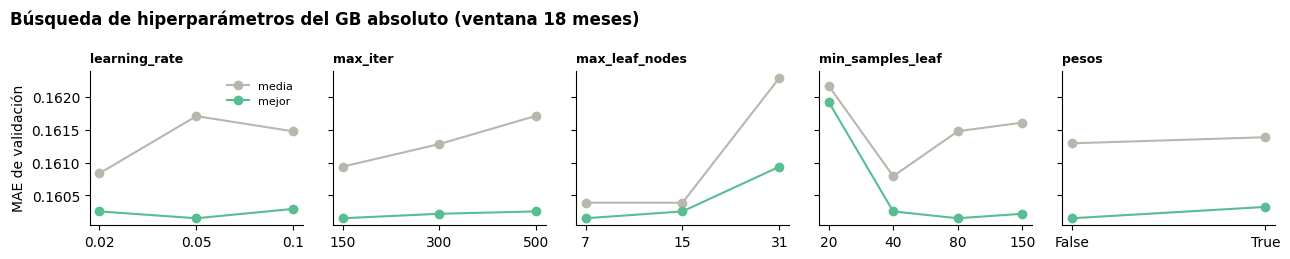

In [25]:
# Cuánto importa cada hiperparámetro del GB absoluto (media del cv_mae por valor, ventana de 18 meses)
gb = busqueda[(busqueda["modelo"] == "GB absoluto") & (busqueda["periodo"] == "ventana 18 meses")].copy()
gb = pd.concat([gb.drop(columns="params"), pd.json_normalize(gb["params"]).set_index(gb.index)], axis=1)
fig, axes = plt.subplots(1, 5, figsize=(13, 2.6), sharey=True)
for ax, col in zip(axes, ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf", "pesos"]):
    m = gb.groupby(col)["cv_mae"].agg(["mean", "min"])
    ax.plot(m.index.astype(str), m["mean"], marker="o", color=GRIS, label="media")
    ax.plot(m.index.astype(str), m["min"], marker="o", color="#56BE91", label="mejor")
    ax.set_title(col, fontsize=9)
axes[0].set_ylabel("MAE de validación"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Búsqueda de hiperparámetros del GB absoluto (ventana 18 meses)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig_hp = guardar(fig, "05_hiperparametros"); plt.show()

## 3. Prueba final en el lote 2

Cada candidato se entrena con su mejor configuración sobre todo su periodo y se evalúa una sola vez en el lote 2. Además del MAE se mira el **Spearman dentro de cada persona**: si el modelo ordena bien las canciones de cada miembro, que es lo que necesita el recomendador del objetivo 2. Las referencias (media y mediana) dan el mismo valor a todas las canciones de una persona, así que no ordenan nada (Spearman sin definir).

In [26]:
def spearman_intra(te, pred):
    s = [spearmanr(e["tasa_no_salto"], pred[e.index]).correlation for _, e in te.groupby("persona")]
    s = [v for v in s if pd.notna(v)]
    return np.mean(s) if s else np.nan

finales, resultados = {}, []
for (periodo, modelo), mejor in mejores.items():
    d = DATOS[periodo]; t, X, te, Xte = d["t"], d["X"], d["te"], d["Xte"]
    y = t["tasa_no_salto"].to_numpy(); w = np.sqrt(t["n_escuchas"].to_numpy()) if mejor["pesos"] else None
    if modelo == "Base: mediana":
        m = Mediana().fit(t["persona"], y); pred = pd.Series(m.predict(te["persona"]), index=te.index)
    else:
        m = ajustar(crear(modelo, **mejor["params"]), X, y, w)
        pred = pd.Series(np.clip(m.predict(Xte), 0, 1), index=te.index)
    finales[(periodo, modelo)] = (m, pred)
    real = te["tasa_no_salto"]
    resultados.append({"periodo": periodo, "modelo": modelo, "cv_mae": mejor["cv_mae"],
                       "lote2_mae": mean_absolute_error(real, pred), "lote2_rmse": mean_squared_error(real, pred) ** 0.5,
                       "lote2_r2": r2_score(real, pred), "lote2_spearman_intra": spearman_intra(te, pred),
                       "lote2_sesgo": (pred - real).mean()})
resultados = pd.DataFrame(resultados).sort_values(["periodo", "lote2_mae"])
resultados.to_csv(SALIDA / "05_resultados_lote2.csv", index=False)
resultados.round(4)

/tmp/ipykernel_1773/4054175434.py:2: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  s = [spearmanr(e["tasa_no_salto"], pred[e.index]).correlation for _, e in te.groupby("persona")]
/tmp/ipykernel_1773/4054175434.py:2: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  s = [spearmanr(e["tasa_no_salto"], pred[e.index]).correlation for _, e in te.groupby("persona")]
/tmp/ipykernel_1773/4054175434.py:2: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  s = [spearmanr(e["tasa_no_salto"], pred[e.index]).correlation for _, e in te.groupby("persona")]
/tmp/ipykernel_1773/4054175434.py:2: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  s = [spearmanr(e["tasa_no_salto"], pred[e.index]).correlation for _, e in te.groupby("persona")]


,periodo,modelo,cv_mae,lote2_mae,lote2_rmse,lote2_r2,lote2_spearman_intra,lote2_sesgo
1,lote 1 completo,Base: mediana,0.1729,0.1944,0.2531,0.3508,NaN,0.0749
2,lote 1 completo,GB absoluto,0.1613,0.1992,0.2613,0.3080,0.1730,0.0869
0,lote 1 completo,Base: media,0.1790,0.2052,0.2558,0.3365,NaN,0.0734
3,lote 1 completo,GB cuadrático,0.1663,0.2064,0.2618,0.3051,0.1595,0.0777
4,lote 1 completo,Ridge,0.1663,0.2067,0.2603,0.3132,0.1345,0.0756
6,ventana 18 meses,Base: mediana,0.1783,0.1843,0.2436,0.3986,NaN,0.0039
7,ventana 18 meses,GB absoluto,0.1602,0.1899,0.2540,0.3462,0.1322,0.0398
8,ventana 18 meses,GB cuadrático,0.1668,0.1929,0.2497,0.3678,0.1968,0.0433
5,ventana 18 meses,Base: media,0.1856,0.1934,0.2427,0.4029,NaN,0.0213
9,ventana 18 meses,Ridge,0.1648,0.1981,0.2511,0.3607,0.1524,0.0351


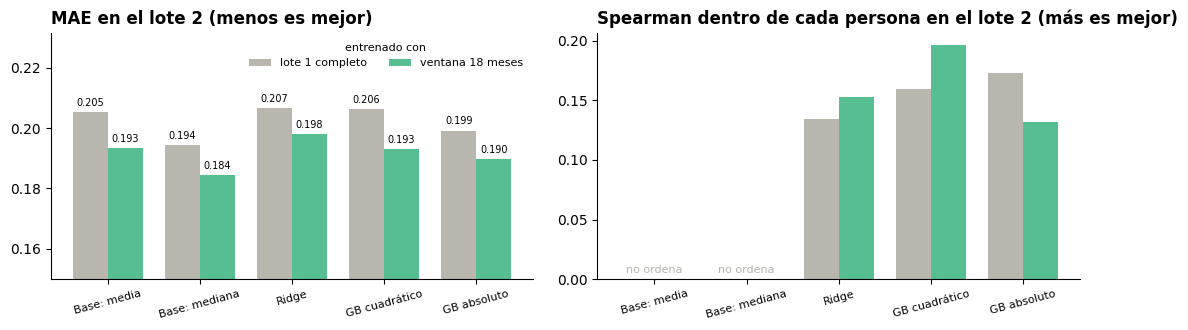

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
orden_m = ["Base: media", "Base: mediana", "Ridge", "GB cuadrático", "GB absoluto"]
x = np.arange(len(orden_m))
for i, (periodo, color) in enumerate([("lote 1 completo", GRIS), ("ventana 18 meses", "#56BE91")]):
    r = resultados[resultados["periodo"] == periodo].set_index("modelo").reindex(orden_m)
    axes[0].bar(x + (i - 0.5) * 0.38, r["lote2_mae"], 0.38, color=color, label=periodo)
    axes[1].bar(x + (i - 0.5) * 0.38, r["lote2_spearman_intra"].fillna(0), 0.38, color=color, label=periodo)
    for xi, v in zip(x, r["lote2_mae"]):
        axes[0].text(xi + (i - 0.5) * 0.38, v + 0.002, f"{v:.3f}", ha="center", fontsize=7)
for ax in axes: ax.set_xticks(x); ax.set_xticklabels(orden_m, fontsize=8, rotation=15)
axes[0].set_ylim(0.15, resultados["lote2_mae"].max() * 1.12); axes[0].set_title("MAE en el lote 2 (menos es mejor)")
for xi in (0, 1):
    axes[1].text(xi, 0.005, "no ordena", ha="center", fontsize=8, color=GRIS)
axes[1].set_title("Spearman dentro de cada persona en el lote 2 (más es mejor)")
axes[0].legend(frameon=False, fontsize=8, title="entrenado con", title_fontsize=8, ncol=2, loc="upper right")
fig.tight_layout(); fig_res = guardar(fig, "05_resultados_lote2"); plt.show()

## 4. Análisis de errores del mejor modelo entrenado

Se mira el GB absoluto con la ventana de 18 meses. Las preguntas: ¿falla más en canciones con pocas escuchas?, ¿en canciones que no estaban en el periodo de entrenamiento?, ¿en alguna persona o contexto?, ¿hacia qué lado se equivoca?

In [28]:
CLAVE_PROD = ("ventana 18 meses", "GB absoluto")
te = DATOS[CLAVE_PROD[0]]["te"].copy()
te["prevista"] = finales[CLAVE_PROD][1]
te["mediana"] = finales[(CLAVE_PROD[0], "Base: mediana")][1]
te["error"] = te["prevista"] - te["tasa_no_salto"]
te["abs_modelo"], te["abs_mediana"] = te["error"].abs(), (te["mediana"] - te["tasa_no_salto"]).abs()
te["escuchas"] = pd.cut(te["n_escuchas"], [4, 7, 12, 25, 10_000], labels=["5-7", "8-12", "13-25", "26+"])
te["franja_txt"] = te["franja"].map(dict(enumerate(["0-4h", "4-8h", "8-12h", "12-16h", "16-20h", "20-24h"])))

def por(col):
    g = te.groupby(col, observed=True).agg(filas=("error", "size"), mae_modelo=("abs_modelo", "mean"),
                                             mae_mediana=("abs_mediana", "mean"), sesgo=("error", "mean"))
    g["mejora_vs_mediana"] = g["mae_mediana"] - g["mae_modelo"]
    return g
analisis = {c: por(c) for c in ["persona", "cancion_conocida", "escuchas", "tipo_dia", "franja_txt"]}
for c, g in analisis.items():
    print(f"\n— por {c}"); display(g.round(3))


— por persona


,filas,mae_modelo,mae_mediana,sesgo,mejora_vs_mediana
persona,,,,,
ander,6932,0.227,0.220,0.035,-0.007
daniel,1988,0.062,0.061,0.058,-0.001



— por cancion_conocida


,filas,mae_modelo,mae_mediana,sesgo,mejora_vs_mediana
cancion_conocida,,,,,
False,2577,0.218,0.224,-0.106,0.006
True,6343,0.178,0.168,0.099,-0.010



— por escuchas


,filas,mae_modelo,mae_mediana,sesgo,mejora_vs_mediana
escuchas,,,,,
5-7,4508,0.179,0.170,0.052,-0.009
8-12,2688,0.193,0.185,0.040,-0.009
13-25,1451,0.204,0.212,0.008,0.008
26+,273,0.253,0.266,0.002,0.013



— por tipo_dia


,filas,mae_modelo,mae_mediana,sesgo,mejora_vs_mediana
tipo_dia,,,,,
fin_semana,1812,0.213,0.208,0.017,-0.005
laborable,7108,0.184,0.178,0.046,-0.006



— por franja_txt


,filas,mae_modelo,mae_mediana,sesgo,mejora_vs_mediana
franja_txt,,,,,
0-4h,759,0.244,0.237,0.032,-0.007
12-16h,2548,0.185,0.179,0.048,-0.006
16-20h,2136,0.184,0.182,0.034,-0.002
20-24h,1869,0.182,0.178,0.010,-0.004
4-8h,284,0.222,0.249,-0.041,0.027
8-12h,1324,0.182,0.163,0.099,-0.019


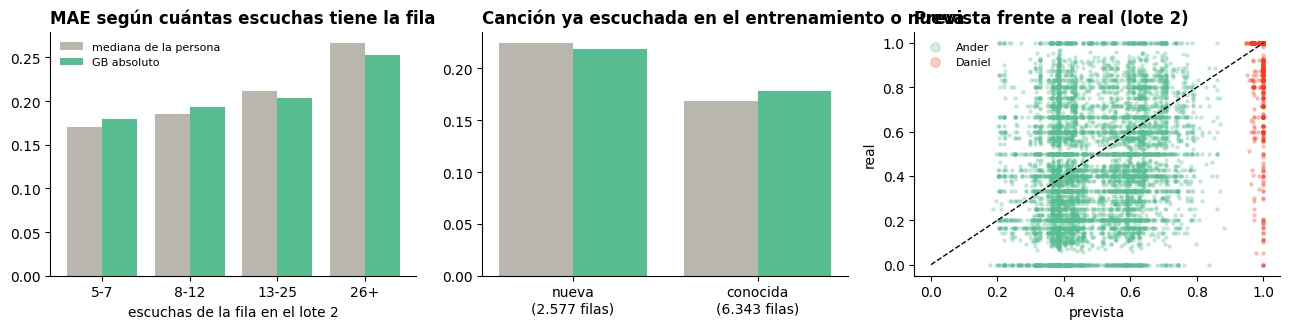

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
g = analisis["escuchas"]
axes[0].bar(np.arange(len(g)) - 0.2, g["mae_mediana"], 0.4, color=GRIS, label="mediana de la persona")
axes[0].bar(np.arange(len(g)) + 0.2, g["mae_modelo"], 0.4, color="#56BE91", label="GB absoluto")
axes[0].set_xticks(range(len(g))); axes[0].set_xticklabels(g.index.astype(str)); axes[0].set_xlabel("escuchas de la fila en el lote 2")
axes[0].set_title("MAE según cuántas escuchas tiene la fila"); axes[0].legend(frameon=False, fontsize=8)
g = analisis["cancion_conocida"].rename(index={True: "conocida", False: "nueva"})
axes[1].bar(np.arange(len(g)) - 0.2, g["mae_mediana"], 0.4, color=GRIS)
axes[1].bar(np.arange(len(g)) + 0.2, g["mae_modelo"], 0.4, color="#56BE91")
axes[1].set_xticks(range(len(g))); axes[1].set_xticklabels([f"{i}\n({n:,} filas)".replace(",", ".") for i, n in zip(g.index, g["filas"])])
axes[1].set_title("Canción ya escuchada en el entrenamiento o nueva")
for p, d in te.groupby("persona"):
    axes[2].scatter(d["prevista"], d["tasa_no_salto"], s=5, alpha=0.25, color=COLOR[p], label=p.capitalize())
axes[2].plot([0, 1], [0, 1], color=NEGRO, lw=1, ls="--")
axes[2].set_xlabel("prevista"); axes[2].set_ylabel("real"); axes[2].set_title("Prevista frente a real (lote 2)")
axes[2].legend(frameon=False, fontsize=8, markerscale=3)
fig.tight_layout(); fig_err = guardar(fig, "05_analisis_errores"); plt.show()

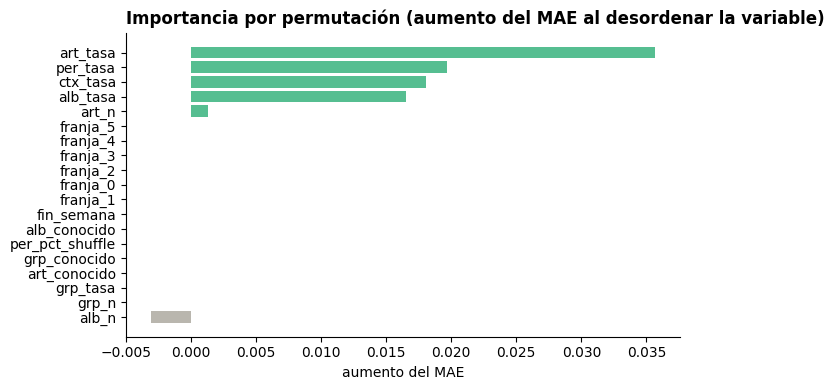

,0
art_tasa,0.0356
per_tasa,0.0197
ctx_tasa,0.0180
alb_tasa,0.0165
art_n,0.0013
franja_1,0.0000
franja_0,0.0000
franja_2,0.0000


In [30]:
# Qué variables pesan más en el GB absoluto (importancia por permutación en el lote 2, medida con MAE)
from sklearn.inspection import permutation_importance
m_prod = finales[CLAVE_PROD][0]
Xte_prod = DATOS[CLAVE_PROD[0]]["Xte"]
imp = permutation_importance(m_prod, Xte_prod, te["tasa_no_salto"], scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEMILLA)
imp = pd.Series(imp.importances_mean, index=Xte_prod.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color=["#56BE91" if v > 0 else GRIS for v in imp.values])
ax.set_title("Importancia por permutación (aumento del MAE al desordenar la variable)"); ax.set_xlabel("aumento del MAE")
fig.tight_layout(); fig_imp = guardar(fig, "05_importancia_variables"); plt.show()
imp.sort_values(ascending=False).round(4).head(8)

## 5. Registro de modelos en MLflow y versión de producción

Cada ejecución registra tres versiones del modelo `playlist_tasa_no_salto`, cada una en su propia ejecución con parámetros, métricas, figuras y el modelo:

| Orden | Modelo | Entrenado con | Papel |
| --- | --- | --- | --- |
| 1 | Ridge | lote 1 completo | el modelo del notebook 03 (lo que había) |
| 2 | GB absoluto ajustado | lote 1 completo | mejora del algoritmo sin cambiar los datos |
| 3 | GB absoluto ajustado | ventana de 18 meses | mejora del algoritmo + política de reentrenamiento del 04 |

**Regla para elegir producción** (fijada antes de mirar el lote 2): la versión con menor MAE de validación dentro de la política de datos elegida en el notebook 04 (ventana de 18 meses), siempre que en el lote 2 no empeore a la versión en producción anterior. Se marca con el alias `produccion`; la anterior queda con el alias `anterior` para poder volver atrás.

In [31]:
NOMBRE_REGISTRO = "playlist_tasa_no_salto"
VERSIONES = [("lote 1 completo", "Ridge"), ("lote 1 completo", "GB absoluto"), ("ventana 18 meses", "GB absoluto")]
MODELOS_DIR = RAIZ / "modelos"; MODELOS_DIR.mkdir(parents=True, exist_ok=True)
registradas = {}

def registrar_version(periodo, modelo):
    m, _ = finales[(periodo, modelo)]
    r = resultados.set_index(["periodo", "modelo"]).loc[(periodo, modelo)]
    mejor = mejores[(periodo, modelo)]
    d = DATOS[periodo]
    if mlflow is None:
        return None
    import mlflow.sklearn as mlflow_sklearn
    from mlflow.models import infer_signature
    with mlflow.start_run(run_name=f"{modelo} · {periodo}") as run:
        mlflow.log_params({"modelo": modelo, "periodo_entrenamiento": periodo, "pesos_sqrt_n": bool(mejor["pesos"]),
                           "desde": f"{d['periodo']['hora_local'].min():%Y-%m-%d}", "hasta": f"{d['periodo']['hora_local'].max():%Y-%m-%d}",
                           "filas_entrenamiento": len(d["t"]), "validacion": "GroupKFold(5) por track_id",
                           **{f"hp_{k}": v for k, v in mejor["params"].items()}})
        mlflow.log_metrics({k: float(r[k]) for k in ["cv_mae", "lote2_mae", "lote2_rmse", "lote2_r2", "lote2_spearman_intra", "lote2_sesgo"] if pd.notna(r[k])})
        for f in [fig_res, fig_err, fig_hp, fig_imp, fig_dist]:
            mlflow.log_artifact(str(f))
        firma = infer_signature(d["X"].head(200), m.predict(d["X"].head(200)))
        confianza = ["sklearn.ensemble._hist_gradient_boosting.predictor.TreePredictor"]
        try:
            info = mlflow.sklearn.log_model(m, name="modelo", signature=firma, input_example=d["X"].head(3),
                                            registered_model_name=NOMBRE_REGISTRO, skops_trusted_types=confianza)
        except TypeError:
            info = mlflow.sklearn.log_model(m, "modelo", signature=firma, registered_model_name=NOMBRE_REGISTRO)
    return info

if mlflow is not None:
    from mlflow import MlflowClient
    cliente = MlflowClient()
    for periodo, modelo in VERSIONES:
        info = registrar_version(periodo, modelo)
        version = getattr(info, "registered_model_version", None)
        if version is None:                                   # versiones de MLflow sin ese atributo
            version = max(int(v.version) for v in cliente.search_model_versions(f"name='{NOMBRE_REGISTRO}'"))
        registradas[(periodo, modelo)] = str(version)
        cliente.set_model_version_tag(NOMBRE_REGISTRO, str(version), "periodo", periodo)
        cliente.set_model_version_tag(NOMBRE_REGISTRO, str(version), "algoritmo", modelo)
        print(f"Registrada versión {version}: {modelo} · {periodo}")

# Copia local para la API (no depende de MLflow): modelo + lista de variables en el orden de entrenamiento
for periodo, modelo in VERSIONES:
    nombre = f"objetivo1_{modelo.split()[0].lower()}_{'ventana18' if 'ventana' in periodo else 'lote1'}.joblib"
    joblib.dump({"modelo": finales[(periodo, modelo)][0], "columnas": COLUMNAS, "periodo": periodo,
                 "algoritmo": modelo, "hiperparametros": mejores[(periodo, modelo)]["params"]}, MODELOS_DIR / nombre)
print("Modelos guardados también en", MODELOS_DIR)

Registered model 'playlist_tasa_no_salto' already exists. Creating a new version of this model...
Created version '13' of model 'playlist_tasa_no_salto'.


Registrada versión 13: Ridge · lote 1 completo


Registered model 'playlist_tasa_no_salto' already exists. Creating a new version of this model...
Created version '14' of model 'playlist_tasa_no_salto'.


Registrada versión 14: GB absoluto · lote 1 completo


Registered model 'playlist_tasa_no_salto' already exists. Creating a new version of this model...
Created version '15' of model 'playlist_tasa_no_salto'.


Registrada versión 15: GB absoluto · ventana 18 meses
Modelos guardados también en /content/drive/MyDrive/proyecto-Ebaluacion1/modelos


In [32]:
# Elección de producción con la regla fijada arriba
res = resultados.set_index(["periodo", "modelo"])
candidatas = [k for k in VERSIONES if k[0] == "ventana 18 meses"]
elegida = min(candidatas, key=lambda k: res.loc[k, "cv_mae"])
anterior = ("lote 1 completo", "Ridge")
no_empeora = res.loc[elegida, "lote2_mae"] <= res.loc[anterior, "lote2_mae"]
if not no_empeora:
    elegida = anterior
justificacion = (f"{elegida[1]} entrenado con {elegida[0]}: menor MAE de validación dentro de la política de la ventana de 18 meses "
                 f"(cv {res.loc[elegida, 'cv_mae']:.3f}); en el lote 2 MAE {res.loc[elegida, 'lote2_mae']:.3f} frente a "
                 f"{res.loc[anterior, 'lote2_mae']:.3f} de la versión anterior y Spearman dentro de cada persona "
                 f"{res.loc[elegida, 'lote2_spearman_intra']:.3f} frente a {res.loc[anterior, 'lote2_spearman_intra']:.3f}.")
print("Pasa a producción:", justificacion)

if mlflow is not None and registradas:
    cliente.set_registered_model_alias(NOMBRE_REGISTRO, "produccion", registradas[elegida])
    cliente.set_registered_model_alias(NOMBRE_REGISTRO, "anterior", registradas[anterior])
    cliente.set_model_version_tag(NOMBRE_REGISTRO, registradas[elegida], "justificacion", justificacion)
    cliente.update_registered_model(NOMBRE_REGISTRO, description=(
        "Regresión de la tasa de no salto por persona × canción × contexto (objetivo 1). "
        "Alias 'produccion': versión que sirve la API; alias 'anterior': la previa, para volver atrás."))
    # Comprobación: se carga el modelo de producción por su alias, como hará la API
    import mlflow.pyfunc
    try:
        prod = mlflow.pyfunc.load_model(f"models:/{NOMBRE_REGISTRO}@produccion")
        X_ej = DATOS[elegida[0]]["Xte"].head(5)
        print("Predicciones del modelo cargado desde el registro:", np.round(prod.predict(X_ej), 3))
    except Exception as e:
        print(f"AVISO: el alias está puesto pero no se pudo cargar el modelo para comprobarlo ({type(e).__name__}: {str(e)[:150]})")
    print("Versiones:", [(v.version, v.aliases if hasattr(v, "aliases") else "") for v in cliente.search_model_versions(f"name='{NOMBRE_REGISTRO}'")])

json.dump({"produccion": {"periodo": elegida[0], "modelo": elegida[1], "version": registradas.get(elegida)},
           "justificacion": justificacion, "resultados": resultados.to_dict("records")},
          open(MODELOS_DIR / "objetivo1_produccion.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=str)

Pasa a producción: GB absoluto entrenado con ventana 18 meses: menor MAE de validación dentro de la política de la ventana de 18 meses (cv 0.160); en el lote 2 MAE 0.190 frente a 0.207 de la versión anterior y Spearman dentro de cada persona 0.132 frente a 0.135.
Predicciones del modelo cargado desde el registro: [0.208 0.48  0.38  0.38  0.318]
Versiones: [(15, []), (14, []), (13, []), (12, []), (11, []), (10, []), (9, []), (8, []), (7, []), (6, []), (5, []), (4, []), (3, []), (2, []), (1, [])]


## 6. Conclusiones

In [33]:
r = resultados.set_index(["periodo", "modelo"])
for k in [("lote 1 completo", "Ridge"), ("lote 1 completo", "Base: mediana"), ("ventana 18 meses", "Base: mediana"),
          ("lote 1 completo", "GB absoluto"), ("ventana 18 meses", "GB absoluto")]:
    print(f"{k[1]:14} · {k[0]:17} cv {r.loc[k, 'cv_mae']:.3f} | lote 2 MAE {r.loc[k, 'lote2_mae']:.3f}, sesgo {r.loc[k, 'lote2_sesgo']:+.3f}, Spearman {r.loc[k, 'lote2_spearman_intra']:.3f}")

Ridge          · lote 1 completo   cv 0.166 | lote 2 MAE 0.207, sesgo +0.076, Spearman 0.135
Base: mediana  · lote 1 completo   cv 0.173 | lote 2 MAE 0.194, sesgo +0.075, Spearman nan
Base: mediana  · ventana 18 meses  cv 0.178 | lote 2 MAE 0.184, sesgo +0.004, Spearman nan
GB absoluto    · lote 1 completo   cv 0.161 | lote 2 MAE 0.199, sesgo +0.087, Spearman 0.173
GB absoluto    · ventana 18 meses  cv 0.160 | lote 2 MAE 0.190, sesgo +0.040, Spearman 0.132


### Qué se ha conseguido

| | MAE validación | MAE lote 2 | Sesgo lote 2 | Spearman dentro de cada persona |
| --- | --- | --- | --- | --- |
| Versión anterior · Ridge · lote 1 (notebook 03) | 0,166 | 0,207 | +0,076 | 0,135 |
| GB absoluto · lote 1 | 0,161 | 0,199 | +0,087 | 0,173 |
| **GB absoluto · ventana 18 meses (producción)** | **0,160** | **0,190** | **+0,040** | **0,132** |
| Referencia: mediana de la persona · ventana 18 meses | 0,178 | 0,184 | +0,004 | no ordena |

- **El GB absoluto con la ventana de 18 meses pasa a producción** con la regla fijada antes de mirar el lote 2. Frente a la versión anterior baja el error en el lote 2 un 8 % (0,207 → 0,190) y reduce el sesgo a la mitad (+0,076 → +0,040).
- **Las dos mejoras suman en el error.**
  - Cambiar a `loss="absolute_error"` encaja con una variable tan asimétrica (el 20 % de las filas valen 1): con los mismos datos, baja el MAE de la Ridge (0,207 → 0,199).
  - Entrenar con los últimos 18 meses (la política del notebook 04) es lo que más baja el error y el sesgo (0,199 → 0,190).
  - La búsqueda de hiperparámetros apenas mueve el error de validación (ver la figura): lo que cambia el resultado es la función de pérdida y el periodo de entrenamiento.

### Lo que no sale bien, y por qué

- **En MAE, la mediana de cada persona sigue ganando en el lote 2** (0,184 frente a 0,190), aunque en validación el modelo es claramente mejor (0,160 frente a 0,178). La diferencia entre las dos pruebas es el drift: lo que el modelo aprende de cada artista y contexto en el pasado vale menos en el presente.
- **La versión de producción no ordena mejor que la anterior** (Spearman 0,132 frente a 0,135). Mejora el nivel (cuánto se salta cada persona), pero no el orden de las canciones. El modelo que mejor ordena es el GB cuadrático con la ventana de 18 meses (0,197), y el GB absoluto con el lote 1 completo también ordena mejor (0,173).
- **Dónde falla el modelo** (análisis de errores):
  - Ander concentra el error (MAE 0,23 frente a 0,06 de Daniel), porque es quien más salta y más ha cambiado.
  - Con las canciones que ya conocía, el modelo es optimista: prevé que se saltarán menos de lo que se saltan (sesgo +0,10).
  - Con las canciones nuevas pasa lo contrario: es pesimista (−0,11) y ahí sí mejora a la mediana.
  - Funciona mejor que la mediana justo en las filas con más escuchas (13 o más), que son las más fiables.
  - La franja de 8 a 12 h es la peor: el modelo prevé +0,10 por encima de lo real.
- **Qué usa el modelo:** sobre todo la tasa del artista, seguida de la de la persona, la del contexto y la del álbum. Lo demás apenas aporta.

### Por qué aun así el modelo, y no la mediana, va a producción

La mediana da **el mismo valor a todas las canciones de una persona**: no sirve para decidir qué canción poner, y el objetivo 1 existe para eso. El modelo de producción da un valor distinto a cada canción y en cada contexto, con el menor error de todos los que ordenan. El MAE se queda como métrica de vigilancia (notebook 04): si el desvío del nivel de una persona se sale de ±0,05 dos meses seguidos, se reentrena.

**Siguiente paso:** como el recomendador necesita sobre todo un buen orden, para la entrega final conviene fijar el Spearman dentro de cada persona como segundo criterio de la regla y evaluar el GB cuadrático con la ventana de 18 meses como nueva versión candidata.

### Registro de modelos

- Modelo registrado: `playlist_tasa_no_salto`. Cada ejecución completa de este notebook añade tres versiones (Ridge con el lote 1, GB absoluto con el lote 1 y GB absoluto con la ventana), con sus parámetros, métricas, figuras, firma de entrada y etiquetas de periodo y algoritmo.
- Alias `produccion` → el GB absoluto con la ventana de la última ejecución; alias `anterior` → la Ridge de esa misma ejecución, para poder volver atrás con un solo cambio. La versión de producción lleva además la justificación como etiqueta.
- La API cargará el modelo con `models:/playlist_tasa_no_salto@produccion`. Hay una copia en `modelos/objetivo1_gb_ventana18.joblib` para cuando no haya servidor de MLflow.

## 7. Guardar los experimentos de MLflow en Drive (solo Colab)

In [34]:
if EN_COLAB and mlflow is not None and mlflow.get_tracking_uri().startswith("sqlite"):
    import shutil
    destino = RAIZ / "mlflow"; destino.mkdir(parents=True, exist_ok=True)
    shutil.copy2("/content/mlflow/mlflow.db", destino / "mlflow.db")
    if Path("/content/mlflow/mlartifacts").exists():
        shutil.copytree("/content/mlflow/mlartifacts", destino / "mlartifacts", dirs_exist_ok=True)
    print("Experimentos copiados a", destino)

Experimentos copiados a /content/drive/MyDrive/proyecto-Ebaluacion1/mlflow
